In [12]:
import pandas as pd

In [13]:
df = pd.read_csv(
    "data/lic_2023-1.csv",
    sep=";",
    encoding="latin-1",
    quotechar='"',
    low_memory=False
)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192813 entries, 0 to 192812
Columns: 110 entries, Codigo to Oferta seleccionada
dtypes: float64(8), int64(32), object(70)
memory usage: 161.8+ MB


In [14]:
def visualizador(df:pd.DataFrame, columnas:list, rango:tuple=(0, 5)) -> None:
    columnas_validas = [col for col in columnas if col in df.columns]
    ini, fin = rango

    for i in range(ini, fin+1):
        for col in columnas_validas:
            print(f"{col}: {df.iloc[i][col]}")
        print()

In [15]:
visualizador(
    df, 
    [
        'Descripcion', 
        'Tipo de Adquisicion', 
        'Tipo', 
        'TipoConvocatoria', 
        'Nombre producto genrico',
        'Rubro1',
        'Rubro2',
        'Rubro3',
        'CodigoProductoONU',
        'Nombre linea Adquisicion',
        'Descripcion linea Adquisicion'
    ],
    rango=(3, 6)
)

Descripcion: INSUMOS DE TRAUMATOLOGIA  EXTREMIDAD SUPERIOR CON EQUIPO EN  COMODATO 
Tipo de Adquisicion: Licitación Pública entre a 2000 y 5000 UTM (LQ)
Tipo: LQ
TipoConvocatoria: 1
Nombre producto genrico: DISPOSITIVOS PROSTÉTICOS DE LA EXTREMIDAD SUPERIOR
Rubro1: EQUIPAMIENTO Y SUMINISTROS MÉDICOS
Rubro2: PRODUCTOS MEDICINALES PARA DEPORTES, PROSTÉTICOS Y ORTOPÉDICOS
Rubro3: DISPOSITIVOS, ACCESORIOS Y SUMINISTROS PROTÉSICOS
CodigoProductoONU: 42242002
Nombre linea Adquisicion: Dispositivos prostéticos de la extremidad superior
Descripcion linea Adquisicion: FIJACION CORACO-ACROMIAL

Descripcion: INSUMOS DE TRAUMATOLOGIA  EXTREMIDAD SUPERIOR CON EQUIPO EN  COMODATO 
Tipo de Adquisicion: Licitación Pública entre a 2000 y 5000 UTM (LQ)
Tipo: LQ
TipoConvocatoria: 1
Nombre producto genrico: DISPOSITIVOS PROSTÉTICOS DE LA EXTREMIDAD SUPERIOR
Rubro1: EQUIPAMIENTO Y SUMINISTROS MÉDICOS
Rubro2: PRODUCTOS MEDICINALES PARA DEPORTES, PROSTÉTICOS Y ORTOPÉDICOS
Rubro3: DISPOSITIVOS, ACCESORIOS Y S

In [16]:
print(sorted(df.columns.to_list()))
print(type(df))

['Cantidad', 'Cantidad Ofertada', 'CantidadAdjudicada', 'CantidadReclamos', 'Codigo', 'CodigoEstado', 'CodigoEstadoLicitacion', 'CodigoExterno', 'CodigoMoneda', 'CodigoOrganismo', 'CodigoProductoONU', 'CodigoProveedor', 'CodigoSucursalProveedor', 'CodigoTipo', 'CodigoUnidad', 'Codigoitem', 'ComunaUnidad', 'Contrato', 'Correlativo', 'CriteriosEvaluacion', 'CriteriosRequisitosAmbientales', 'CriteriosRequisitosSociales', 'Descripcion', 'Descripcion linea Adquisicion', 'DescripcionCriteriosRequisitosAmbientales', 'DescripcionCriteriosRequisitosSociales', 'DescripcionCriteriosRequisitosSociales.1', 'DescripcionProveedor', 'DireccionEntrega', 'DireccionUnidad', 'DireccionVisita', 'EsBaseTipo', 'EsRenovable', 'Estado', 'Estado Oferta', 'EstadoCS', 'EstadoEtapas', 'EstadoPublicidadOfertas', 'Estimacion', 'Etapas', 'ExtensionPlazo', 'FechaActoAperturaEconomica', 'FechaActoAperturaTecnica', 'FechaAdjudicacion', 'FechaAprobacion', 'FechaCierre', 'FechaCreacion', 'FechaEntregaAntecedentes', 'Fecha

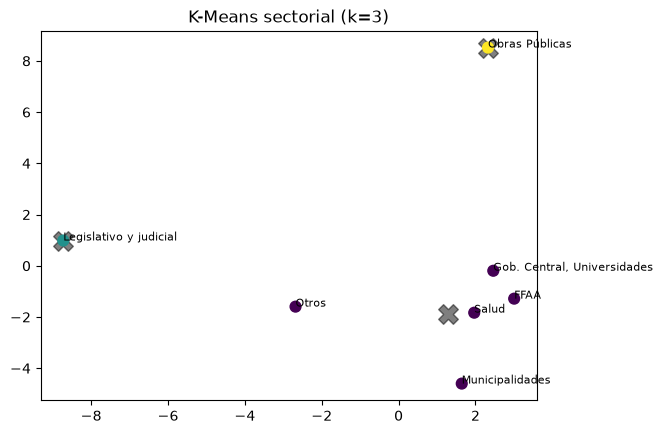

sector
FFAA                           0
Gob. Central, Universidades    0
Municipalidades                0
Otros                          0
Salud                          0
Legislativo y judicial         1
Obras Públicas                 2
dtype: int32


In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
k = 3
df = pd.read_csv("data/serie_tiempo_limpia.csv")
df = df[df["sector"] != "SINDATO"]
P = df.pivot(index="Semana", columns="sector", values="Volumen_Licitaciones")
X = StandardScaler().fit_transform(P).T
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels = km.fit_predict(X)
pca = PCA(n_components=2)
X2 = pca.fit_transform(X)
C2 = pca.transform(km.cluster_centers_)

plt.scatter(C2[:, 0], C2[:, 1], marker='X', s=200, c='black', alpha=0.5)
plt.scatter(X2[:, 0], X2[:, 1], s=60, c=labels)
for nombre, (x, y) in zip(P.columns, X2):
    plt.annotate(nombre, (x, y), fontsize=8)
plt.title(f"K-Means sectorial (k={k})")
plt.show()

print(pd.Series(labels, index=P.columns).sort_values())

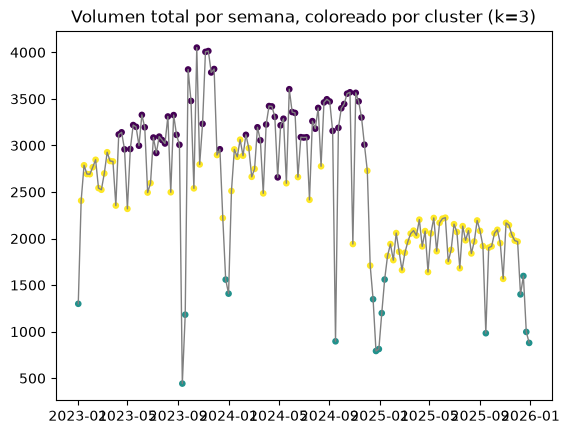

sector  FFAA  Gob. Central, Universidades  Legislativo y judicial  \
0       1.03                         1.01                    0.52   
1      -1.60                        -1.88                   -1.44   
2      -0.43                        -0.36                   -0.09   

sector  Municipalidades  Obras Públicas  Otros  Salud  
0                  0.91            0.82   0.71   0.73  
1                 -1.57           -0.95  -1.69  -2.16  
2                 -0.35           -0.40  -0.18  -0.11  


In [35]:
k = 3
df = df[df["sector"] != "SINDATO"]
P = df.pivot(index="Semana", columns="sector", values="Volumen_Licitaciones")
fechas = pd.to_datetime(P.index.str.split("/").str[0])
X = StandardScaler().fit_transform(P)

km = KMeans(n_clusters=k, n_init=20, random_state=42)
labels = km.fit_predict(X)

plt.plot(fechas, P.sum(axis=1), color="gray", lw=1)
plt.scatter(fechas, P.sum(axis=1), c=labels, s=14)
plt.title(f"Volumen total por semana, coloreado por cluster (k={k})")
plt.show()

print(pd.DataFrame(km.cluster_centers_, columns=P.columns).round(2))